# 7. Dashboard y despliegue

**URL pública:** `https://<servicio>.onrender.com` *(se completa al desplegar)*.

El dashboard es una aplicación Dash multipágina (`use_pages=True`) con tres secciones. Cada elemento responde a una
pregunta de un usuario real: ¿dónde se espera actividad el próximo mes?, ¿qué dicen los datos?, ¿qué modelo usar y por
qué confiar en él?

In [1]:
# Localiza la raíz del proyecto (la carpeta con src/ y app.py) para poder importar los módulos de src/
import sys
from pathlib import Path
raiz = Path.cwd().resolve()
while not ((raiz / "src").is_dir() and (raiz / "app.py").exists()):
    raiz = raiz.parent
sys.path.insert(0, str(raiz))
# Librerías de análisis y módulos propios: configuración, datos, EDA, evaluación y utilidades del libro
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from src import config as cfg, datos, eda, evaluacion as ev
from src.libro import md, tabla, mostrar_plotly
from src.eda import es, p_fmt
# Estilo común de los gráficos, semilla global (SEMILLA = 42) y formato de las tablas
eda.configurar_graficos()
cfg.fijar_semillas()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

## 7.1 Arquitectura

```text
proyecto/
├── app.py                 # crea la app (Dash + dash-bootstrap-components) y expone server para gunicorn
├── pages/
│   ├── contexto.py        # sección 1: problema, pregunta, datos, metodología, limitaciones
│   ├── eda.py             # sección 2: filtros globales y callbacks que actualizan todos los gráficos
│   └── modelos.py         # sección 3: líderes, predicción en vivo, diagnóstico, SHAP, pruebas, modelo original
├── src/
│   ├── original_model.py  # clase ModeloOriginalAB (compatible con scikit-learn)
│   ├── data.py            # carga y caché de datos (lru_cache: una sola lectura por proceso)
│   ├── plots.py           # plantilla Plotly única y funciones de gráficos reutilizables
│   ├── artefactos.py      # carga perezosa de los modelos serializados
│   └── explicacion.py     # SHAP (TreeSHAP o por permutaciones)
├── artifacts/             # modelos .joblib + metadata.json + predicciones de ida y vuelta
├── data/app/              # datos livianos precalculados para el dashboard
├── assets/estilo.css      # paleta de 5 colores y tipografía
├── tests/                 # pytest: árbol CART, modelo original, artefactos
├── book/                  # este Jupyter Book
├── requirements.txt       # dependencias del dashboard con versiones exactas
└── render.yaml            # despliegue en Render
```

**Separación de responsabilidades.** La interfaz (pages/) no calcula modelos: lee datos precalculados
(`scripts/preparar_datos_app.py`) y carga los artefactos solo cuando se pide una predicción. El servidor nunca
entrena ni optimiza.

## 7.2 Decisiones de diseño

- **Tema y paleta.** Bootstrap FLATLY con barra de navegación fija; cinco colores (tinta, azul petróleo, naranja, gris y
  arena). El naranja se reserva para el modelo original y para resaltar.
- **Plantilla Plotly única** (`src/plots.py`): títulos, ejes con unidades, hover informativo y tipografía legible en
  pantallas pequeñas.
- **Interpretación junto a cada figura.** Cada gráfico tiene una frase de lectura calculada con los datos filtrados.
- **Rendimiento.** Datos cargados una vez (`lru_cache`), modelos cargados al primer uso, `prevent_initial_call` en los
  callbacks que esperan una acción, `no_update` cuando no hay cambios y muestras de tamaño fijo en los gráficos de
  dispersión.
- **Robustez.** El formulario valida tipo y rango de cada variable (rangos del entrenamiento) y muestra los errores con
  `dbc.Alert`; un error en la predicción se informa sin detener la aplicación.
- **Accesibilidad.** Contraste alto, la información no depende solo del color (valores en texto y tablas) y etiquetas
  en todos los controles.

## 7.3 Capturas de pantalla

**1 contexto**

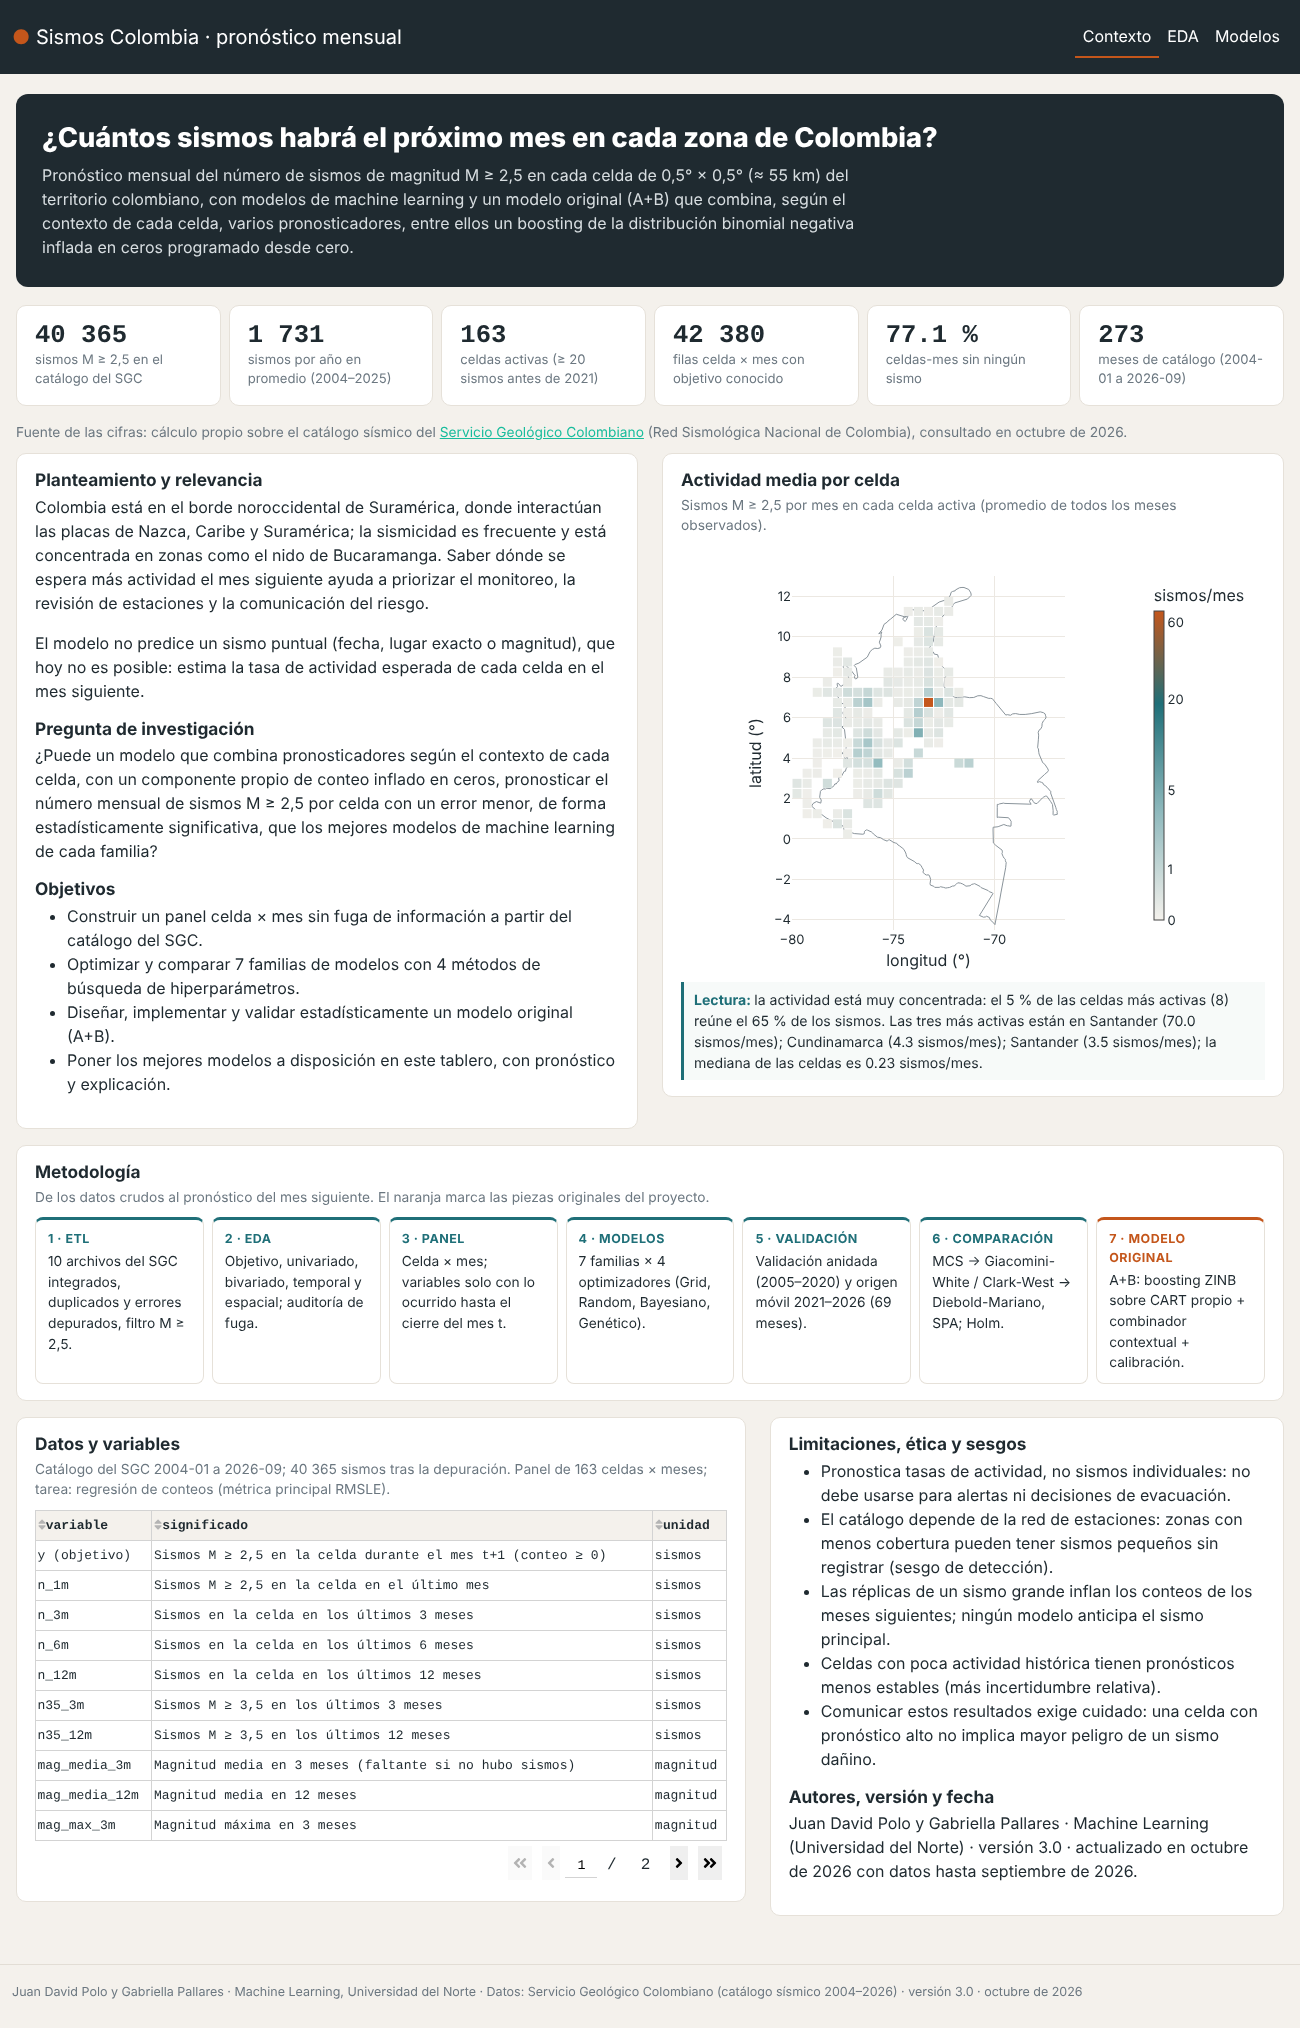

**2 eda**

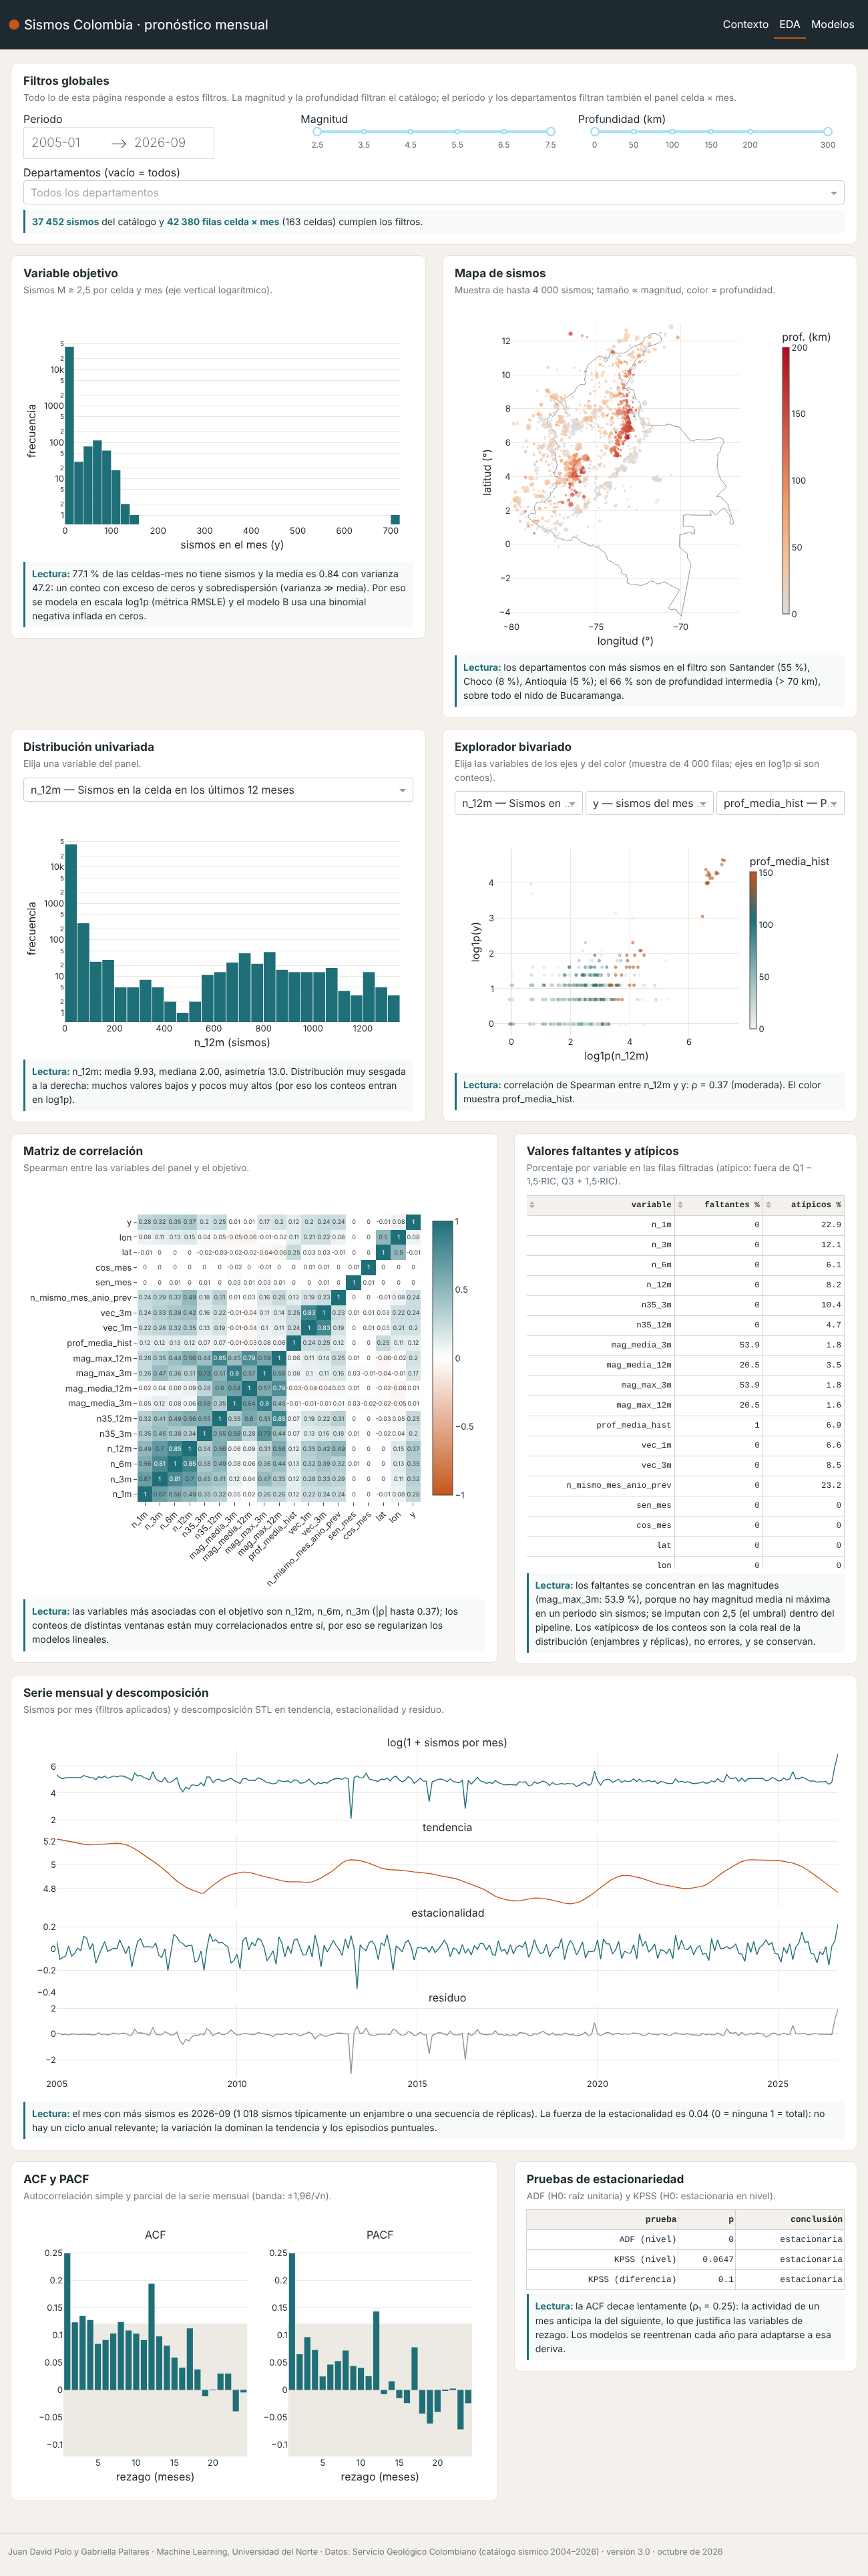

**3 modelos**

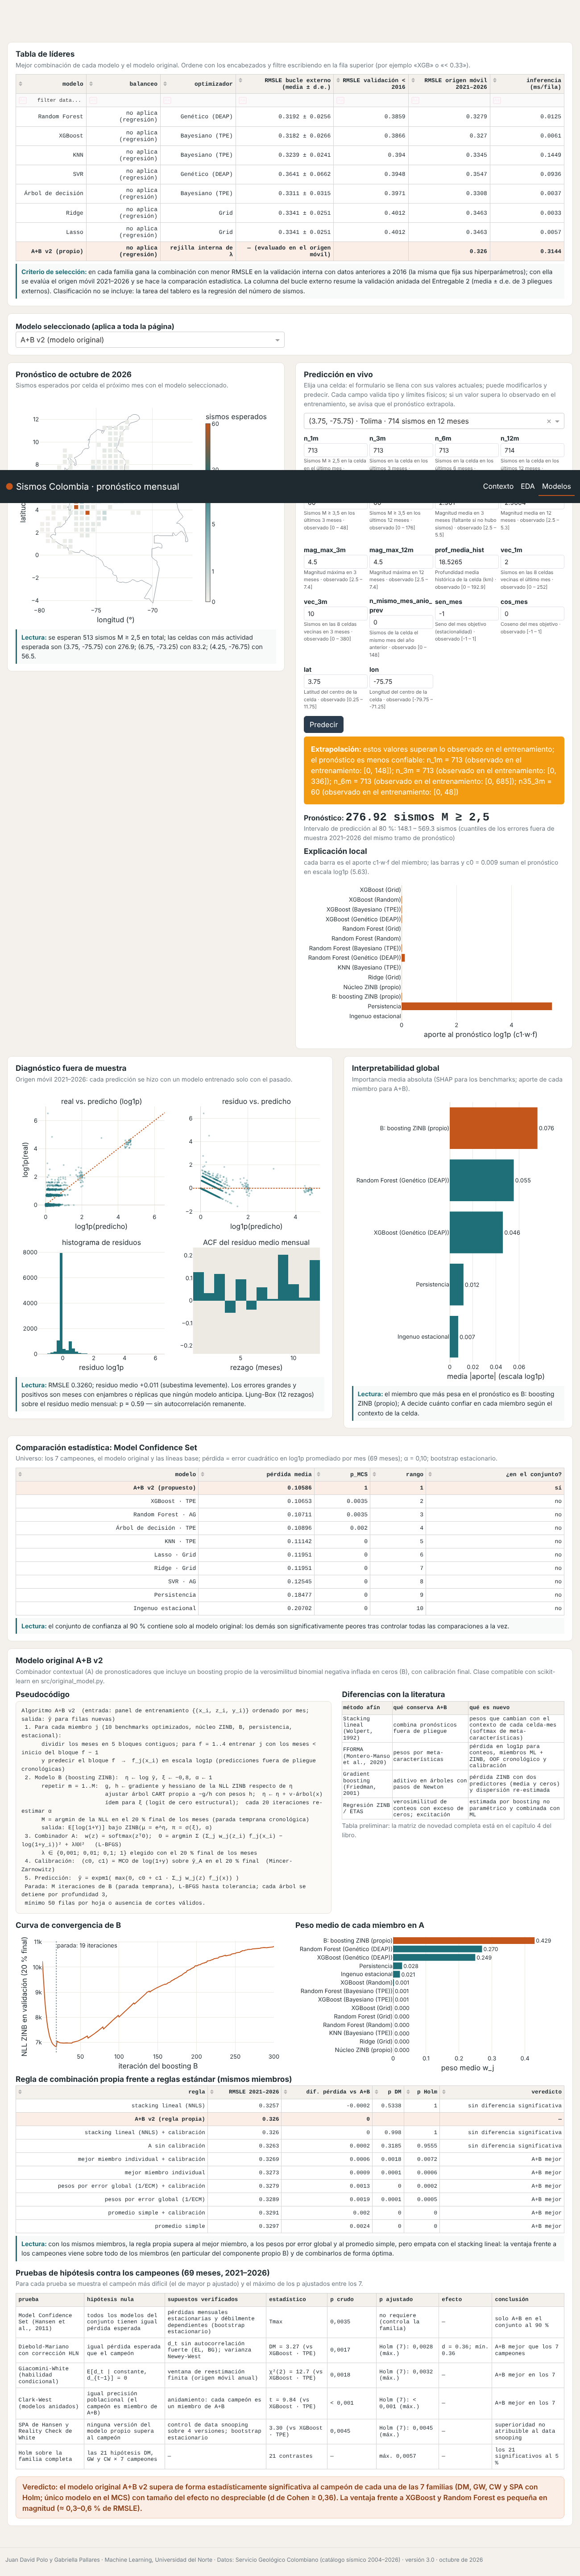

In [2]:
from IPython.display import Image, display
from pathlib import Path
for f in sorted((Path(cfg.RAIZ) / "book" / "figuras").glob("dashboard_*.png")):
    md(f"**{f.stem.replace('dashboard_', '').replace('_', ' ').capitalize()}**")
    display(Image(filename=str(f), width=900))

## 7.4 Guía de despliegue en Render

1. Verificar localmente: `pip install -r requirements.txt` y `python app.py` (abre `http://127.0.0.1:8050`).
2. Subir el repositorio a GitHub (incluye `artifacts/` y `data/app/`).
3. En Render: **New → Blueprint** (lee `render.yaml`) o **New → Web Service** con *Build command*
   `pip install -r requirements.txt` y *Start command* `gunicorn app:server --workers 1 --threads 2 --timeout 120 --preload`;
   variable de entorno `PYTHON_VERSION=3.9.25` (la versión con la que se serializaron los modelos).
4. Revisar los registros de construcción y abrir la URL pública; probar las tres páginas y una predicción.
5. El plan gratuito suspende el servicio por inactividad: abrir la URL unos minutos antes de la sustentación.